This notebook shows the 3D FDTD simulation of a low-refractive index polymer periodic structure supporting Fano type resonance in Tidy3D. 
The unit cell contains a single square shaped polymer structure with equal periodicity in the x and y direction. The incident radiation is linearly polarized along the x direction.
The chosen frequency range is in the C band.


In [1]:
import os
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

import tidy3d as td
import tidy3d.web as web
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore", message='install "ipywidgets" for Jupyter support') #prevents unnecessary warning

In [143]:
#clears the cache if repeating the simulation
from tidy3d.web.cache import clear as clear_cache
clear_cache() 

Specify the wavelength range and refractive index of substrate and the dielectric structure (polymer in this case)

In [25]:
nm = 1e-3 # for converting nanometer unit to microns. microns is the default unit in tidy3D
Nfreq = 2000  #number of frequency points
wavelengths = nm * np.linspace(1530, 1590, Nfreq) #desired wavelength range
freqs = td.constants.C_0 / wavelengths   #warning: value of C is um/s in tidy3d
freq0 = freqs[len(freqs) // 2]
freqw = freqs[0] - freqs[-1]

n_SiO2 = 1.45   #refractive index of SiO2 substrate
n_poly = 1.599   #refractive index of polymer
SiO2 = td.Medium(permittivity=n_SiO2**2)   #dielectric permittivity of SiO2
poly = td.Medium(permittivity=n_poly**2)   #dielectric permittivity of polymer

Specify properties of the unit cell and simulation region

In [8]:
Px = Py = P = 1060 * nm  # periodicity of unit cell in x and y (in microns unit)
t = 1050 * nm  # thickness (height) of polymer bar
L = 940 * nm  # length of the polymer bar 

dl = P / 32 # spatial resolution of FDTD grid

spc = 1.7 # space between resonators and source
Lz = spc + t + t + spc + spc # total size of the simulation region in z 
sim_size = [Px, Py, Lz]  #simulation size in x, y, z directions

In [9]:
#create the SiO2 substrate and Polymer bar. Specify their centre position and size in the geometry.
# sio2 substrate
substrate = td.Structure(
    geometry=td.Box(
        #center=[0, 0, -Lz / 2],
        center=[0, 0, (-Lz+spc+0.8) / 2],
        size=[td.inf, td.inf, 2 * (spc + t)],
    ),
    medium=SiO2,
    name="substrate",
)

#polymer bar
cell = td.Structure(
    geometry=td.Box(
        center=[0, 0, (t+0.8) / 2.0],
        size=[L, L, t],
    ),
    medium=poly,
    name="cell",
)


In [10]:
#Excitation source
# time dependence of source
gaussian = td.GaussianPulse(freq0=freq0, fwidth=freqw)

# plane wave source
source = td.PlaneWave(
    source_time=gaussian,
    direction="-",
    size=(td.inf, td.inf, 0),
    center=(0, 0, Lz / 2 - spc + 2 * dl + 1),
    pol_angle=0.0,
)

In [122]:
#Monitors

# monitor fields on other side of structure (substrate side) at a range of frequencies to study farfield 
zpos= -1*dl*60
farfield = td.FluxMonitor(
    center=[0.0, 0.0, zpos],
    size=[td.inf, td.inf, 0],
    freqs=freqs,
    normal_dir='-',
    name="farfield",
)

#Monitor to extract electric and magnetic field distribution in the xy plane 
#use this monitor when the exact resonance wavelength (f_res) is known. Omit using this in the simulation otherwise/use an array of frequencies.
res_wl = 1557.02927 *nm
f_res = td.constants.C_0 / res_wl 
field_xy_monitor = td.FieldMonitor(
    center=(0, 0, (t+0.8)/ 2.0),         
    size=(Px, Py, 0),               
    freqs=[f_res],                   
    name="field_xy",
)

#Monitor to extract electric and magnetic field distribution in the yz plane
#use this monitor when the exact resonance wavelength (f_res) is known. Omit using this in the simulation otherwise.
field_yz_monitor = td.FieldMonitor(
    center=(0, 0, (t+0.8)/ 2.0),
    size=(0, Py, t + 0.4),           
    freqs=[f_res],
    name="field_yz",
)


#Monitors for multipole decomposition

#define tidy3D  volume
z_buffer = 0.04
mp_center = (0, 0, (t+0.8+ z_buffer) / 2.0)
mp_size = (Px + 0.08, Py + 0.08, t + z_buffer)

mp_field_monitor = td.FieldMonitor(
    center=mp_center, size=mp_size, freqs=[f_res],
    fields=["Ex", "Ey", "Ez"], colocate=False, name="mp_fields",
)
mp_eps_monitor = td.PermittivityMonitor(
    center=mp_center, size=mp_size, freqs=[f_res], name="mp_eps",
)

In [29]:
#FDTD grid

# Finer grid (10 nm) in and around the polymer bar
bar_mesh_override = td.MeshOverrideStructure(
    geometry=td.Box(
        center=(0, 0, (t + 0.8) / 2.0),
        size=(L + 0.08, L + 0.08, t + 0.08),
    ),
    dl=(0.010, 0.010, 0.010),  # 10 nm resolution 
)

# redefine grid specification with the finer mesh
grid_spec = td.GridSpec(
    grid_x=td.AutoGrid(min_steps_per_wvl=32), 
    grid_y=td.AutoGrid(min_steps_per_wvl=32),
    grid_z=td.AutoGrid(min_steps_per_wvl=32), override_structures=[bar_mesh_override],
)


In [16]:
#Run time calculation
Q_est = 2000  #estimated Q factor
f0 = td.C_0 / 1.55  #estimated resonance frequency
photon_lifetime= Q_est/(2*np.pi*f0)
run_time_est = 10 * photon_lifetime 
print(f"run_time_est = {run_time_est}")

run_time_est = 1.645739612251605e-11


In [17]:
run_time = 2.0e-11

In [142]:
#Define the reference (just with the substrate) and the metasurface simulation
#in the monitors= [] line, keep only the monitors you need
sim_empty = td.Simulation(
    size=sim_size,
    grid_spec=grid_spec,
    structures=[substrate],
    sources=[source],
    monitors=[farfield, field_xy_monitor, field_yz_monitor, mp_field_monitor, mp_eps_monitor],
    run_time=run_time/10,
    symmetry=(-1, 1, 0),
    shutoff=0,
    courant=0.99,
    boundary_spec=td.BoundarySpec(
        x=td.Boundary.periodic(), y=td.Boundary.periodic(), z=td.Boundary.pml()
    ),
)                                                     # simulation of reference run with just the substrate


sim_polymer = td.Simulation(
    size=sim_size,
    grid_spec=grid_spec,
    structures= [substrate, cell],
    sources=[source],
    monitors=[farfield, field_xy_monitor, field_yz_monitor, mp_field_monitor, mp_eps_monitor],
    run_time=run_time,
    symmetry=(-1, 1, 0),
    courant=0.99,
    shutoff=0,
    boundary_spec=td.BoundarySpec(
        x=td.Boundary.periodic(), y=td.Boundary.periodic(), z=td.Boundary.pml(num_layers=20)
    ),
)                                                     # simulation of full metasurface



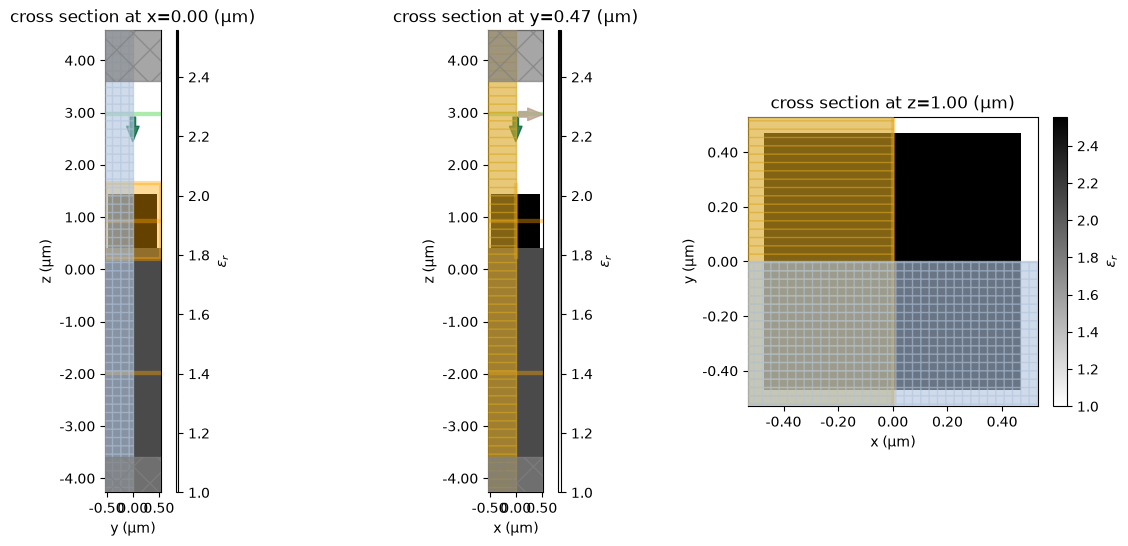

In [70]:
# Structure visualization in various planes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
sim_polymer.plot_eps(x=0, ax=ax1)
sim_polymer.plot_eps(y=L/2, ax=ax2)
sim_polymer.plot_eps(z=1, ax=ax3)
plt.show()

In [144]:
#Run the simulation

batch = web.Batch(
    simulations={
        "normalization": sim_empty,
        "metasurface": sim_polymer,
    },
    verbose=False,
)

results = batch.run(path_dir="polymer_metasurface")

14:54:05 IST WARNING: Simulation has 1.05e+06 time steps. The 'run_time' may be 
             unnecessarily large, unless there are very long-lived resonances.  

In [145]:
batch_data = batch.load(path_dir="polymer_metasurface") #load data from web.run()

In [173]:
#Extract and save datas for post processing in python
#flux_data = sim_data["flux_monitor"].flux
flux_norm = batch_data["normalization"]["farfield"].flux
freqs = flux_norm.f.values          # Frequencies in Hz     1D numpy array    #might have to replace flux with farfield
wavelengths = td.C_0 / freqs        # Wavelengths in um     1D numpy array
transmission = batch_data["metasurface"]["farfield"].flux / flux_norm   
T = transmission.values  #1D numpy array
# Save numpy array as a compressed NumPy archive (.npz)
np.savez(
    "transmission_data.npz",
    freqs=freqs,
    wavelengths=wavelengths,
    T=T
)



In [ ]:
#Plot of transmission spectra with curve fitting

In [147]:
T = np.clip(T, 0, None) 
wavelengths_nm = wavelengths/nm
res_wl_nm = wavelengths_nm[np.argmin(T)]  #resonance wavelength in nm

#selecting narrow range of data around resoance wavelength
window = 15.0 
mask = np.abs(wavelengths_nm - res_wl_nm) < window
lam_w, T_w = wavelengths_nm[mask], T[mask]

#inital parameters for curve fitting
p0 = [res_wl_nm, 1.0, 0.1, np.min(T_w), np.max(T_w) - np.min(T_w)]
bounds = ([res_wl_nm - window, 1e-3, -100.0, -0.1, 0.0], [res_wl_nm + window, window * 2, 100.0, 1.5, 5.0],)

#define Fano fitting function
def fano(lam, lam0, gamma, q, T_bg, T_amp):
    eps = 2.0 * (lam - lam0) / gamma
    return T_bg + T_amp * ((eps + q) ** 2) / (eps ** 2 + 1.0)

#performing curve fit
from scipy.optimize import curve_fit
popt, pcov = curve_fit(fano, lam_w, T_w, p0=p0, bounds=bounds, maxfev=50000)
lam0, gamma, q, T_bg, T_amp = popt
Q = lam0 / abs(gamma)

#print fitted parameters
print(f"λ₀ = {lam0:.5f} nm | FWHM = {abs(gamma):.3f} nm | Q = {Q:.0f} | q = {q:.3f}")


λ₀ = 1557.02927 nm | FWHM = 0.785 nm | Q = 1984 | q = 0.059


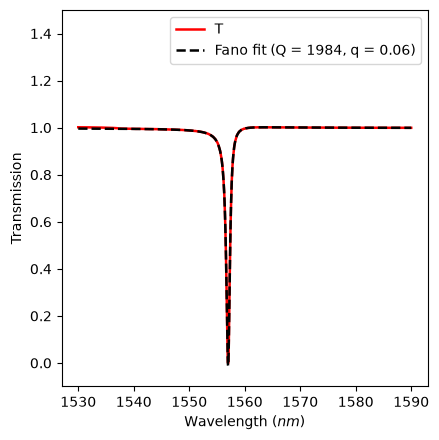

In [159]:
# Plot transmission data with Fano curve
T_fit= fano(wavelengths_nm, lam0, gamma, q, T_bg, T_amp)

fig, ax = plt.subplots(1, 1, figsize=(4.5, 4.5))
ax.plot(wavelengths_nm, T, color="red", linewidth=1.8, label=r"T")
ax.plot( wavelengths_nm, T_fit, color="black", linestyle="--", linewidth=1.8, label=f"Fano fit (Q = {Q:.0f}, q = {q:.2f})",)

ax.set_xlabel("Wavelength ($nm$)")
ax.set_ylabel("Transmission")
# ax.set_xlim([1530, 1590])
ax.set_ylim([-0.1, 1.5])
ax.legend()
plt.tight_layout()
fig.savefig("Transmission_spectra.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
#Calculate near field intensity enhancement

In [149]:
#define function to divide the metasurface results with the data from the empty simulation
def get_E_enhancement(mon_name, f_val):
    mon_atom = sim_data_atom[mon_name]
    mon_empty = sim_data_empty[mon_name]
    
    # Call .sel() on the individual field components (.Ex, .Ey, .Ez)
    Ex_a = mon_atom.Ex.sel(f=f_val, method="nearest")
    Ey_a = mon_atom.Ey.sel(f=f_val, method="nearest")
    Ez_a = mon_atom.Ez.sel(f=f_val, method="nearest")
    
    Ex_e = mon_empty.Ex.sel(f=f_val, method="nearest")
    Ey_e = mon_empty.Ey.sel(f=f_val, method="nearest")
    Ez_e = mon_empty.Ez.sel(f=f_val, method="nearest")
    
    E2_atom = (np.abs(Ex_a)**2 + np.abs(Ey_a)**2 + np.abs(Ez_a)**2).squeeze()
    E2_empty = (np.abs(Ex_e)**2 + np.abs(Ey_e)**2 + np.abs(Ez_e)**2).squeeze()
    
    return E2_atom / float(E2_empty.mean())


def get_H_enhancement(mon_name, f_val):
    mon_atom = sim_data_atom[mon_name]
    mon_empty = sim_data_empty[mon_name]
    
    Hx_a = mon_atom.Hx.sel(f=f_val, method="nearest")
    Hy_a = mon_atom.Hy.sel(f=f_val, method="nearest")
    Hz_a = mon_atom.Hz.sel(f=f_val, method="nearest")
    
    Hx_e = mon_empty.Hx.sel(f=f_val, method="nearest")
    Hy_e = mon_empty.Hy.sel(f=f_val, method="nearest")
    Hz_e = mon_empty.Hz.sel(f=f_val, method="nearest")
    
    H2_atom = (np.abs(Hx_a)**2 + np.abs(Hy_a)**2 + np.abs(Hz_a)**2).squeeze()
    H2_empty = (np.abs(Hx_e)**2 + np.abs(Hy_e)**2 + np.abs(Hz_e)**2).squeeze()
    
    return H2_atom / float(H2_empty.mean())

In [174]:
# 1. Extract the exact recorded frequency scalars
f_res=freqs[np.argmin(T)]
E_f_arr_xy = sim_data_atom["field_xy"].Ex.f.values
E_f_arr_yz = sim_data_atom["field_yz"].Ex.f.values
H_f_arr_xy = sim_data_atom["field_xy"].Hx.f.values
H_f_arr_yz = sim_data_atom["field_yz"].Hx.f.values

E_f_plot_xy = E_f_arr_xy[np.argmin(np.abs(E_f_arr_xy - f_res))].item()
E_f_plot_yz = E_f_arr_yz[np.argmin(np.abs(E_f_arr_yz - f_res))].item()
H_f_plot_xy = H_f_arr_xy[np.argmin(np.abs(H_f_arr_xy - f_res))].item()
H_f_plot_yz = H_f_arr_yz[np.argmin(np.abs(H_f_arr_yz - f_res))].item()
lam_plot_nm = (td.C_0 / E_f_plot_xy) * 1e3


In [151]:
#calculate the enahancement values
en_E_xy = get_E_enhancement("field_xy", E_f_plot_xy)
en_E_yz = get_E_enhancement("field_yz", E_f_plot_yz)

en_H_xy = get_H_enhancement("field_xy", H_f_plot_xy)
en_H_yz = get_H_enhancement("field_yz", H_f_plot_yz)


In [152]:
#Extract in-plane vector components for vector overlay
mon_xy = sim_data_atom["field_xy"]
Ex_xy = mon_xy.Ex.sel(f=E_f_plot_xy, method="nearest").squeeze()
Ey_xy = mon_xy.Ey.sel(f=E_f_plot_xy, method="nearest").squeeze()
Hx_xy = mon_xy.Hx.sel(f=H_f_plot_xy, method="nearest").squeeze()
Hy_xy = mon_xy.Hy.sel(f=H_f_plot_xy, method="nearest").squeeze()

mon_yz = sim_data_atom["field_yz"]
Ey_yz = mon_yz.Ey.sel(f=E_f_plot_yz, method="nearest").squeeze()
Ez_yz = mon_yz.Ez.sel(f=E_f_plot_yz, method="nearest").squeeze()
Hy_yz = mon_yz.Hy.sel(f=H_f_plot_yz, method="nearest").squeeze()
Hz_yz = mon_yz.Hz.sel(f=H_f_plot_yz, method="nearest").squeeze()

In [186]:
#save variables to analyze later

np.savez(
    "nearfield_enhancement_values.npz",
    en_E_xy=en_E_xy,
    en_E_yz=en_E_yz,
    en_H_xy=en_H_xy,
    en_H_yz=en_H_yz,
)

np.savez(
    "nearfield_vector_component_values.npz",
    Ex_xy=Ex_xy,
    Ey_xy=Ey_xy,
    Hx_xy=Hx_xy,
    Hy_xy=Hy_xy,
    Ey_yz=Ey_yz,
    Ez_yz=Ez_yz,
    Hy_yz=Hy_yz,
    Hz_yz=Hz_yz,
)

In [177]:
#E1, E2 will be x and y components when considering XY plane. y and z components when considering the YZ plane
def get_normalized_quiver(E1, E2, step: int = 9):
    """Generates downsampled 2D meshgrids and unit-normalized real field vectors for vector overlay."""
    dim1, dim2 = E1.dims
    Grid1, Grid2 = np.meshgrid(E1[dim1].values[::step], E1[dim2].values[::step], indexing="ij")
    
    U = E1.values[::step, ::step].real
    V = E2.values[::step, ::step].real
    
    mag = np.hypot(U, V) + 1e-12
    U_norm, V_norm = U / mag, V / mag
    
    return Grid1, Grid2, U_norm, V_norm


In [ ]:
#Near field Plots

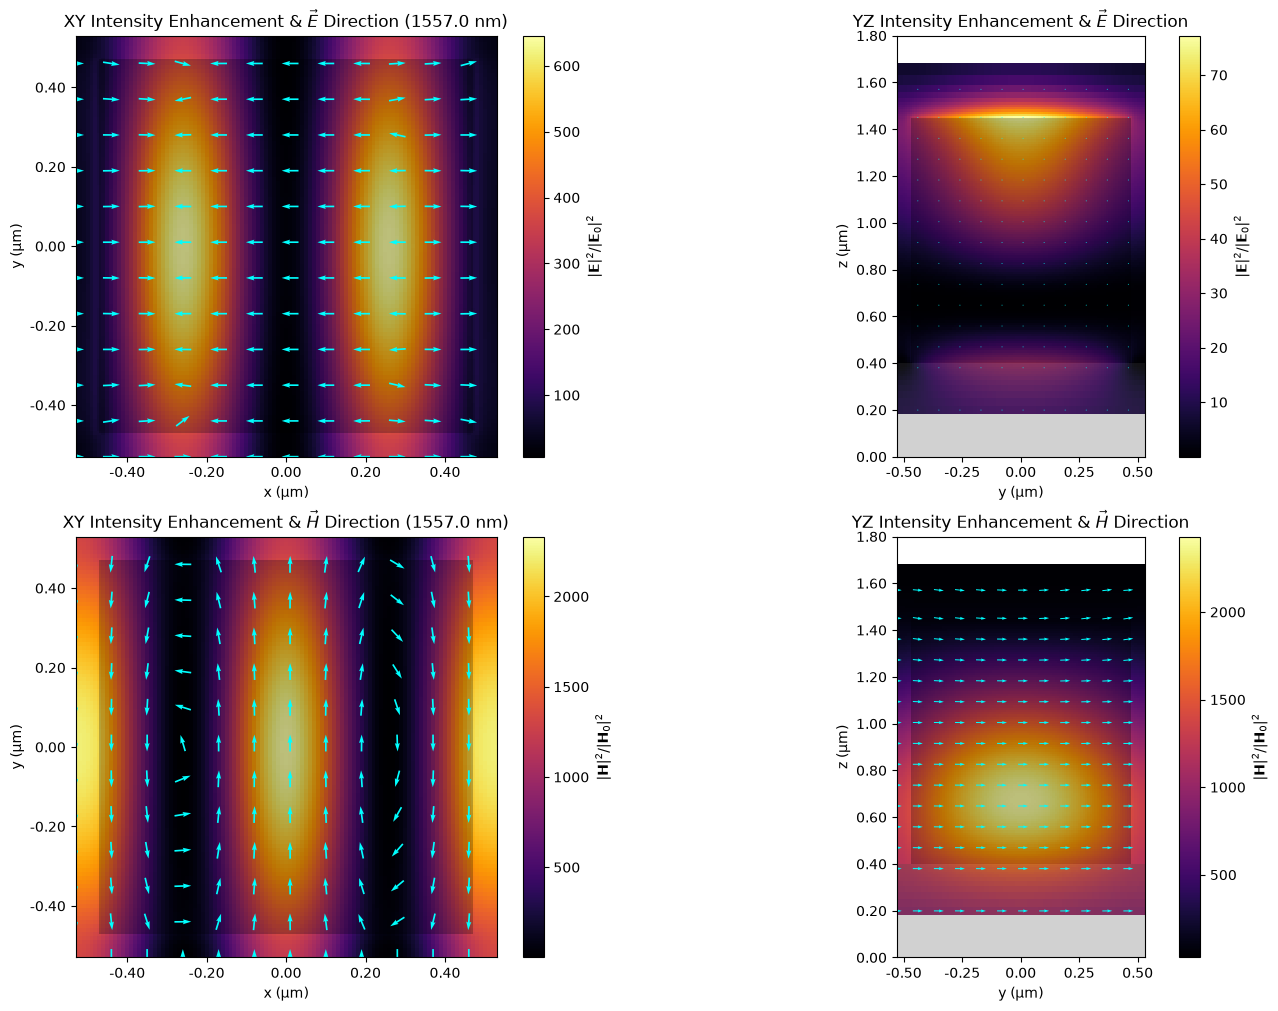

In [187]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)

# Electric field intensity enhancement


# Get the quiver for vector overlay
X_xy, Y_xy, U_xy_norm, V_xy_norm = get_normalized_quiver(Ex_xy, Ey_xy, step)
Y_yz, Z_yz, U_yz_norm, V_yz_norm = get_normalized_quiver(Ey_yz, Ez_yz, step)

# Top-Left (ax1): Near-field intensity enhancement in the XY plane
en_E_xy.plot.pcolormesh(
    x="x",
    y="y",
    ax=ax1,
    cmap="inferno",
    cbar_kwargs={"label": r"$|\mathbf{E}|^2 / |\mathbf{E}_0|^2$"},
)
sim_data_atom.simulation.plot_structures_eps(z=t / 2.0, ax=ax1, cbar=False, alpha=0.25)
ax1.quiver(X_xy, Y_xy, U_xy_norm, V_xy_norm, color="cyan", pivot="mid", scale=25, width=0.004)
ax1.set_title(rf"XY Intensity Enhancement & $\vec{{E}}$ Direction ({lam_plot_nm:.1f} nm)")

# Top-Right (ax2): Near-field intensity enhancement in the YZ plane
en_E_yz.plot.pcolormesh(
    x="y",
    y="z",
    ax=ax2,
    cmap="inferno",
    cbar_kwargs={"label": r"$|\mathbf{E}|^2 / |\mathbf{E}_0|^2$"},
)
sim_data_atom.simulation.plot_structures_eps(x=0, ax=ax2, cbar=False, alpha=0.25)
ax2.quiver(Y_yz, Z_yz, U_yz_norm, V_yz_norm, color="cyan", pivot="mid", scale=25, width=0.004)
ax2.set_ylim([0, 1.8])
ax2.set_title(r"YZ Intensity Enhancement & $\vec{E}$ Direction")

#--------------------------------------------------------------------------------------------------------
# Magnetic field intensity enhancement

# Get the quiver for vector overlay
X_xy, Y_xy, U_xy_norm, V_xy_norm = get_normalized_quiver(Hx_xy, Hy_xy, step)
Y_yz, Z_yz, U_yz_norm, V_yz_norm = get_normalized_quiver(Hy_yz, Hz_yz, step)

# Bottom-Left (ax3): Near-field intensity enhancement in the XY plane
en_H_xy.plot.pcolormesh(
    x="x",
    y="y",
    ax=ax3,
    cmap="inferno",
    cbar_kwargs={"label": r"$|\mathbf{H}|^2 / |\mathbf{H}_0|^2$"},
)
sim_data_atom.simulation.plot_structures_eps(z=t / 2.0, ax=ax3, cbar=False, alpha=0.25)
ax3.quiver(X_xy, Y_xy, U_xy_norm, V_xy_norm, color="cyan", pivot="mid", scale=25, width=0.004)
ax3.set_title(rf"XY Intensity Enhancement & $\vec{{H}}$ Direction ({lam_plot_nm:.1f} nm)")

# Bottom-Right (ax4): Near-field intensity enhancement in the YZ plane
en_H_yz.plot.pcolormesh(
    x="y",
    y="z",
    ax=ax4,
    cmap="inferno",
    cbar_kwargs={"label": r"$|\mathbf{H}|^2 / |\mathbf{H}_0|^2$"},
)
sim_data_atom.simulation.plot_structures_eps(x=0, ax=ax4, cbar=False, alpha=0.25)
ax4.quiver(Y_yz, Z_yz, U_yz_norm, V_yz_norm, color="cyan", pivot="mid", scale=25, width=0.004)
ax4.set_ylim([0, 1.8])
ax4.set_title(r"YZ Intensity Enhancement & $\vec{H}$ Direction")

fig.savefig("Efield_Hfield_enhancement.png", dpi=700, bbox_inches="tight")
plt.show()


In [ ]:
#Multipole decomposition  

In [135]:
# Define the Cartesian multipole decomposition function
def compute_multipoles(sim_data, field_mon_name="mp_fields", eps_mon_name="mp_eps", eps_bg=1.0):
    """
    Computes Cartesian multipole scattering cross-sections (ED, MD, TD, EQ, MQ)
    from 3D FieldMonitor and PermittivityMonitor data.
    """
    f_data = sim_data[field_mon_name]
    e_data = sim_data[eps_mon_name]
    
    freqs = f_data.Ex.f.values
    omega = 2 * np.pi * freqs
    c0 = td.C_0  # um/s
    k0 = omega / c0
    eps0 = td.EPSILON_0
    
    # Extract grid coordinates from the permittivity monitor
    x = e_data.eps_xx.x.values
    y = e_data.eps_xx.y.values
    z = e_data.eps_xx.z.values
    
    # Grid cell volume dV (um^3)
    dx = np.gradient(x)
    dy = np.gradient(y)
    dz = np.gradient(z)
    dV = dx[:, None, None] * dy[None, :, None] * dz[None, None, :]
    
    # 3D coordinate grids centered at the meta-atom center
    X, Y, Z = np.meshgrid(x - np.mean(x), y - np.mean(y), z - np.mean(z), indexing="ij")
    r_vec = np.stack([X, Y, Z], axis=0)  # shape: (3, Nx, Ny, Nz)
    r2 = np.sum(r_vec**2, axis=0)
    
    C_ED, C_MD, C_TD, C_EQ, C_MQ, C_tot = [], [], [], [], [], []
    
    for idx, f_val in enumerate(freqs):
        w = omega[idx]
        k = k0[idx]


        # Interpolate E-field onto the exact permittivity grid with edge extrapolation
        interp_kwargs = {"fill_value": "extrapolate"}
        Ex = f_data.Ex.interp(x=x, y=y, z=z, kwargs=interp_kwargs).isel(f=idx).values
        Ey = f_data.Ey.interp(x=x, y=y, z=z, kwargs=interp_kwargs).isel(f=idx).values
        Ez = f_data.Ez.interp(x=x, y=y, z=z, kwargs=interp_kwargs).isel(f=idx).values
        E = np.stack([Ex, Ey, Ez], axis=0)
        
        eps_x = e_data.eps_xx.isel(f=idx).values
        eps_y = e_data.eps_yy.isel(f=idx).values
        eps_z = e_data.eps_zz.isel(f=idx).values
        eps_r = np.stack([eps_x, eps_y, eps_z], axis=0)
        
        # Induced polarization current density J = -i * omega * eps0 * (eps_r - eps_bg) * E
        J = -1j * w * eps0 * (eps_r - eps_bg) * E
        
        # 1. Electric Dipole (p)
        p = (1j / w) * np.sum(J * dV, axis=(1, 2, 3))
        
        # 2. Magnetic Dipole (m)
        r_cross_J = np.cross(r_vec, J, axis=0)
        m = 0.5 * np.sum(r_cross_J * dV, axis=(1, 2, 3))
        
        # 3. Toroidal Dipole (T)
        r_dot_J = np.sum(r_vec * J, axis=0)
        T_integrand = r_dot_J[None, ...] * r_vec - 2.0 * r2[None, ...] * J
        T_dip = (1.0 / (10.0 * c0)) * np.sum(T_integrand * dV, axis=(1, 2, 3))
        
        # Total effective electric dipole (p + i*k*T)
        p_tot = p + 1j * k * T_dip
        
        # 4. Electric Quadrupole tensor (Qe)
        Qe = np.zeros((3, 3), dtype=complex)
        for a in range(3):
            for b in range(3):
                delta_ab = 1.0 if a == b else 0.0
                term = 3.0 * (r_vec[b] * J[a] + r_vec[a] * J[b]) - 2.0 * r_dot_J * delta_ab
                Qe[a, b] = (1j / w) * np.sum(term * dV)
                
        # 5. Magnetic Quadrupole tensor (Qm)
        Qm = np.zeros((3, 3), dtype=complex)
        for a in range(3):
            for b in range(3):
                term = r_vec[a] * r_cross_J[b] + r_vec[b] * r_cross_J[a]
                Qm[a, b] = (1.0 / 3.0) * np.sum(term * dV)
                
        # Scattered power contributions
        P_ed = np.sum(np.abs(p)**2)
        P_td = np.sum(np.abs(1j * k * T_dip)**2)
        P_ed_tot = np.sum(np.abs(p_tot)**2)
        P_md = np.sum(np.abs(m / c0)**2)
        P_eq = (k**2 / 120.0) * np.sum(np.abs(Qe)**2)
        P_mq = (k**2 / 120.0) * np.sum(np.abs(Qm / c0)**2)
        
        C_ED.append(P_ed)
        C_TD.append(P_td)
        C_MD.append(P_md)
        C_EQ.append(P_eq)
        C_MQ.append(P_mq)
        C_tot.append(P_ed_tot + P_md + P_eq + P_mq)
        
    lam_nm = (c0 / freqs) * 1e3
    return {
        "lam_nm": lam_nm,
        "ED": np.array(C_ED),
        "TD": np.array(C_TD),
        "MD": np.array(C_MD),
        "EQ": np.array(C_EQ),
        "MQ": np.array(C_MQ),
        "Total": np.array(C_tot),
    }

In [161]:
sim_data_mp = web.run(sim_polymer, task_name="polymer_metasurface", path="polymer_metasurface.hdf5")

16:15:44 IST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=12589784;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2073f142-a3ff-46d7-b76a-f170f4a45572\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=12589785;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2073f142-a3ff-46d7-b76a-f170f4a45572\taskId]8;;\]8;id=12589784;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2073f142-a3ff-46d7-b76a-f170f4a45572\=]8;;\]8;id=12589786;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2073f142-a3ff-46d7-b76a-f170f4a45572\fdve]8;;\]8;id=12589784;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2073f142-a3ff-46d7-b76a-f170f4a45572\-2073f142-a3f]8;;\
             ]8;id=12589784;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2073f142-a3ff-46d7-b76a-f170f4a45572\f-46d7-b76a-f170f4a45572']8;;\.

Raw multipole scattering values: {'ED': 1.5362553967981294e-32, 'MD': 7.445770783252661e-30, 'TD': 8.444139899476628e-32, 'EQ': 4.212947517122996e-30, 'MQ': 1.065652458631942e-32}


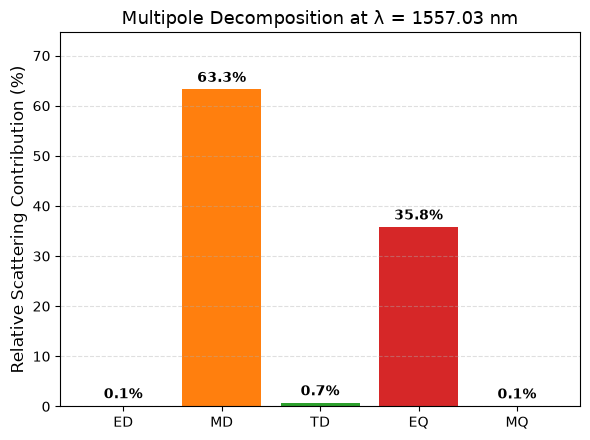

In [167]:
# multipole calculation on simulation data

mp = compute_multipoles(sim_data_mp, field_mon_name="mp_fields", eps_mon_name="mp_eps", eps_bg=1.0)

labels = ["ED", "MD", "TD", "EQ", "MQ"]
values = [mp[k].item() for k in labels]
print("Raw multipole scattering values:", dict(zip(labels, values)))

total_sum = sum(values)
if total_sum <= 0 or np.isnan(total_sum):
    raise ValueError("Multipole sum is zero or NaN. Check that mp_center and mp_size overlap your polymer bars.")

percentages = [(v / total_sum) * 100.0 for v in values]

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(labels, percentages, color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"])

for bar, pct in zip(bars, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{pct:.1f}%",
        ha="center",
        fontweight="bold",
    )

ax.set_ylabel("Relative Scattering Contribution (%)", fontsize=12)
ax.set_title(f"Multipole Decomposition at λ = {mp['lam_nm'].item():.2f} nm", fontsize=13)
ax.set_ylim([0, max(percentages) * 1.18])
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
fig.savefig("Multipole_decomposition.png", dpi=400, bbox_inches="tight")
plt.show()